# Private by Construction Within a Stated Boundary

## Closed-schema local agent packets with cryptographic and acoustic verification

Technical artifact paper with disclosed AI assistance. All benchmark payloads are synthetic and no recordings of people are collected.

## Abstract

Privacy claims for agents frequently exceed the behavior actually enforced at their input and output boundaries. This artifact evaluates a narrow alternative with explicit assumptions. A local packet boundary accepts only enumerated intents, enumerated status, bounded measurements and a sequence number. It rejects additional fields and free-form strings before serialization. Seven plaintext bytes are authenticated and encrypted with AES-GCM into a thirty-five-byte acoustic envelope. Replay control is atomic, audit entries contain ciphertext digests rather than payloads, and network attempts are instrumented and denied in the Python and Node benchmark paths. Separate Ed25519 experiments verify actual detached signatures. The acoustic experiment invokes the real AirCast JavaScript modem, including PCM generation, Gaussian noise, Goertzel demodulation, corrected Hamming codewords and CRC validation. Results include authenticated recovery counts, software latency, airtime, effective plaintext goodput and Wilson intervals. The work demonstrates correctness of a directly nonpersonal synthetic boundary, not differential privacy, acoustic secrecy or protection from a compromised host. Numeric covert channels, traffic analysis and physical acoustic reception remain explicit limitations.

## 1. Problem and scope

An agent can expose information by placing it in a prompt, tool parameter, log entry or network request. Encrypting a message after unnecessary personal fields have already been collected does not eliminate that exposure. A privacy-oriented boundary must define both what data can enter and what can leave.

The question in this artifact is whether a small offline workflow can enforce a closed, directly nonpersonal packet contract while retaining executable cryptographic and transport checks. The objective is not to infer that every numerical measurement is semantically free of personal information. It is to eliminate direct collection of names, addresses, institutions, locations and unconstrained narrative in the measured workflow.

The experiment uses generated measurements and software acoustic channels. No participant, microphone recording, human voice, real location or private document is involved. No network model, hosted speech service or telemetry endpoint is required.

## 2. Threat model

The receiver must reject malformed or tampered packets, a sender without the symmetric key, repeated deliveries and attempts to add unsupported fields. The audit must reveal changes to its serialized chain without logging cleartext payloads. The benchmark transport must make no unobserved Python or Node network connection.

The trusted computing base includes the local process, cryptographic library, packet schema, key storage in memory and AirCast DSP implementation. An attacker who controls that host can read plaintext and keys. A malicious source can also encode information in allowed numeric fields or packet timing. Those threats are not solved by a closed schema.

Acoustic transmission is treated as publicly observable. Privacy derives from a correctly implemented authenticated-encryption boundary and secret production keys, not from inaudibility or the choice of a speaker channel. The optional anonymous identity primitive proves control of an ephemeral signing key; it does not establish a person, trusted issuer or external affiliation.

## 3. Packet boundary

The packet has exactly five fields. Version is fixed to one. Sequence is a bounded integer. Intent belongs to measure, status or acknowledge. Level belongs to the enumerated status set. Measurement is an integer within a fixed range.

Unsupported fields, free-form intents, boolean values masquerading as integers and invalid ranges fail validation before encryption. No rejected raw input is included in the results ledger. The attack record stores only the attack category, attempt count and rejection count.

The Python benchmark packs the schema into seven bytes using a fixed big-endian layout. The browser helper uses JSON serialization of the same closed field contract. These are distinct serializers and are not claimed to be byte-compatible. The shared acoustic engine transports binary envelopes without interpreting their application semantics.

Python nonce and replay state are guarded by a lock. The asynchronous browser helper reserves an in-flight nonce before decryption, preventing concurrent deliveries from both passing the replay check. It requires a canonical nonce encoding so equivalent base64 spellings cannot create distinct replay identifiers.

Receiver state has a documented capacity. A saturated receiver denies further packets rather than silently evicting history and admitting a replay. A production system would need a reviewed session rotation and durable replay policy; this artifact does not implement a distributed replay database.

## 4. Cryptographic design

AES-GCM uses a 256-bit key, a twelve-byte nonce and fixed version-specific additional authenticated data. The seven-byte plaintext gains a sixteen-byte authentication tag. Including the nonce produces a thirty-five-byte envelope.

The application default creates a fresh key and random nonces locally. Browser keys are nonextractable and never persisted. This does not imply memory zeroization. Python objects and browser internals can retain sensitive material for some period, and a compromised process remains in scope for a separate security review.

For reproducible channel waveforms the benchmark uses a published synthetic fixture key and deterministic nonrepeating test nonces. This key protects no sensitive data and must never be used in production. The benchmark validates cryptographic functionality; it is not a new security proof of AES-GCM or a confidentiality claim for public test ciphertexts.

Ed25519 detached signatures are generated and verified in a separate experiment using an actual cryptographic implementation. The sixty-four-byte signature is not appended to the measured thirty-five-byte acoustic envelope. Wire authentication in that experiment is symmetric AEAD. This distinction prevents signing overhead and identity semantics from being hidden in the transport claim.

## 5. Audit and offline egress

The audit chain stores an enumerated acceptance/rejection event, a ciphertext SHA-256 digest, the preceding chain hash and the current entry hash. It contains neither the application payload nor a personal identity. The experiment verifies the chain, mutates an event and checks that verification fails.

A hash chain is tamper-evident only relative to a trusted stored chain head. An attacker capable of rewriting the complete chain and its expected head can recompute it. No trusted remote anchoring, signed timestamp service or production audit-storage guarantee is claimed.

The Python benchmark wraps connection, UDP-send and name-resolution entry points with counters that deny attempts. The Node acoustic process similarly disables socket connection attempts. The measured counter is recorded in the result metadata. These hooks demonstrate the evaluated process path, not a complete host firewall or proof that unrelated native libraries can never transmit.

No hosted model or acoustic recognition service is invoked. Dependency installation and the public research-data fetch in the separate ARC package are outside the offline measurement interval.

## 6. Acoustic transport

AirCast uses four frequency-shift keyed data tones. It is not an OFDM implementation. Audible and near-ultrasonic profiles are software configurations; no physical reliability or room-range measurement is inferred.

Protocol version two uses a revised marker and an encoded-length field, Hamming(7,4) codewords stored in bytes, and CRC-16. The syndrome table matches the parity-check matrix. Codewords are corrected before checking integrity against the decoded payload, so a correctable single-bit error can recover a valid frame.

Framing rejects invalid padding, odd codeword counts, truncation and trailing frame bytes. CRC is an error-detection mechanism rather than an authenticator. After framing succeeds, AEAD verification still decides whether the application envelope can be accepted.

The detector assumes known preamble and symbol alignment in software loopback. This controlled experiment does not measure asynchronous reception from a microphone. Speaker frequency response, automatic gain control, clock drift, room reflections and environmental interference require a separate physical evaluation.

The revised audible profile uses twelve-millisecond symbols. A bounded waveform synthesizer prevents unbounded sample allocation. Short encrypted packets are suitable for the experiment, while large JSON objects still incur substantial airtime. Displayed waveform duration is derived from the actual sample count, not estimated from a marketing claim.

## 7. Experimental protocol

The cryptographic experiment performs 1,000 valid seal/open round trips and 1,000 actual Ed25519 sign/verify operations. It measures elapsed time with a performance counter and reports median, p95 and aggregate duration.

Six attack categories each contain one hundred attempts. They cover ciphertext modification, the wrong key, replay, truncation, an unsupported field and an invalid enum. Expected exception categories are counted as rejection; unrelated programming exceptions are not treated as successful security behavior.

For the acoustic experiment, twelve deterministic envelopes are passed through each condition in the predeclared final SNR sweep. Gaussian noise is generated from a recorded seed. Both coded and genuinely uncoded packets are synthesized and demodulated. Each decoded envelope is then authenticated by a fresh receiver fixture for that independent channel condition.

The same application payload is used in both modes, but coded and uncoded frames have different lengths and airtime. The comparison is equal input SNR and symbol duration, not equal energy per information bit or equal delivery latency. It therefore cannot establish a coding gain independent of framing overhead.

Per-condition results report authenticated recoveries, any incorrectly accepted payload, measured decode time, frame airtime and effective plaintext goodput. Wilson intervals use the twelve recovery trials; their width is visible even for zero or complete recovery. No smoothing or theoretical curve is mixed into a measured rate.

## 8. Results

All one thousand valid cryptographic round trips and signature verifications complete successfully. All six categories reject one hundred of one hundred targeted attempts. The audit is valid before mutation and rejects the modified chain. The instrumented benchmark paths report zero network attempts.

These are controlled implementation checks, not a distributional claim that every possible attack has been tested. Fixed-bit corruption and wrong-key tests cannot replace cryptographic review, nonce analysis or adversarial fuzzing of an expanded application protocol.

The acoustic table is generated from actual PCM and decoded bytes. Very noisy conditions produce failed delivery without accepting a different authenticated payload. Higher-SNR conditions recover packets, with the exact counts and intervals recorded in the appendix and notebook.

The coded frame's longer airtime can reduce effective goodput when both modes recover equally well. At other conditions, codeword correction may affect recovery. The artifact reports the observed curve rather than assuming that error correction always improves the displayed score.

Latency in this experiment is software processing time. Acoustic airtime is a different quantity and is reported separately. Confusing fast software loopback with fast physical transmission would materially overstate usability.

## 9. Privacy interpretation and limitations

The strict privacy result is zero direct personal-field collection in these synthetic fixtures and no network attempt in the instrumented evaluation path. It is not a proof of semantic zero-PII for arbitrary agents. A malicious agent could encode sensitive bits in an allowed sequence, bounded measurement, message count or timing pattern.

There is no differential-privacy mechanism, anonymity-set measurement, speech anonymization model, secure enclave or verified memory erasure. The system does not protect a key from a compromised host. Public fixture keys intentionally provide no confidentiality for benchmark examples.

Acoustic observers can see timing, duration and waveform activity. Encryption hides application contents only under its normal key and nonce assumptions; it does not hide that communication occurred. A physical receiver study and traffic-analysis experiment are needed before making stronger claims.

The cryptographic and transport paths use separate validity checks, so a CRC-valid frame is not labelled an authenticated identity. The anonymous signature demo is a local capability object, not an issued passport, recognized credential or proof of human identity.

## 10. Reproducibility and conclusion

The implementation, original DSP snapshot, dependency lock, source digests, raw channel observations, measured tables and executable paper notebook are included. Default runs use no private information or model service. The deterministic fixture key reproduces waveforms while production defaults remain randomized.

A narrow closed schema, real cryptography, replay control and explicitly disabled egress can create an inspectable local boundary. Its value depends on stating what is enforced and what remains outside scope. The artifact demonstrates that boundary without claiming acoustic secrecy, universal data-loss prevention or unmeasured human privacy outcomes.

## References

1. NIST. Recommendation for Block Cipher Modes of Operation, Galois/Counter Mode and GMAC. SP 800-38D, 2007. [NIST publication](https://doi.org/10.6028/NIST.SP.800-38D).
2. Simon Josefsson and Ilari Liusvaara. Edwards-Curve Digital Signature Algorithm, RFC 8032, 2017. [RFC 8032](https://www.rfc-editor.org/rfc/rfc8032).
3. Cryptography project. [Authenticated encryption API](https://cryptography.io/en/latest/hazmat/primitives/aead/).
4. Cryptography project. [Ed25519 API](https://cryptography.io/en/latest/hazmat/primitives/asymmetric/ed25519/).

## Executable reproduction

The next cell reruns the actual benchmark. Only the bundled public data and synthetic fixtures are used. Install the pinned requirements first. Hardware-dependent timings may change. Unavailable GPU backends are not relabelled as CPU results.

## Recomputed empirical results

| experiment | trials | successes | rejected | rate | median_ms | p95_ms | total_ms |
| --- | --- | --- | --- | --- | --- | --- | --- |
| AEAD_and_replay_state | 1000 | 1000 | 0 | 1.000000 | 0.002916 | 0.003458 | 3.134265 |
| Ed25519_detached_signatures | 1000 | 1000 | 0 | 1.000000 | 0.200458 | 0.211047 | 202.064492 |
| tampered_ciphertext | 100 | 0 | 100 | 1.000000 | 0.002083 | 0.002337 | 2.740958 |
| wrong_key | 100 | 0 | 100 | 1.000000 | 0.002333 | 0.002625 | 0.252790 |
| replay | 100 | 0 | 100 | 1.000000 | 0.001625 | 0.001711 | 0.163666 |
| truncated | 100 | 0 | 100 | 1.000000 | 0.000375 | 0.000417 | 0.037293 |
| unknown_field | 100 | 0 | 100 | 1.000000 | 0.000584 | 0.000669 | 0.061875 |
| invalid_enum | 100 | 0 | 100 | 1.000000 | 0.000667 | 0.000791 | 0.069334 |


## Recomputed acoustic results

| snr_db | mode | trials | authenticated_recoveries | unsafe_accepts | recovery_rate | wilson95_low | wilson95_high | airtime_seconds | plaintext_goodput_bps | median_ms | p95_ms | total_ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| -24 | coded | 12 | 0 | 0 | 0.000000 | 0.000000 | 0.242494 | 3.866621 | 0.000000 | 5.960104 | 6.570194 | 72.401877 |
| -24 | raw | 12 | 0 | 0 | 0.000000 | 0.000000 | 0.242494 | 2.187256 | 0.000000 | 3.256667 | 3.865335 | 40.229709 |
| -18 | coded | 12 | 0 | 0 | 0.000000 | 0.000000 | 0.242494 | 3.866621 | 0.000000 | 5.906354 | 6.010990 | 70.869376 |
| -18 | raw | 12 | 0 | 0 | 0.000000 | 0.000000 | 0.242494 | 2.187256 | 0.000000 | 3.227229 | 3.253055 | 38.717625 |
| -12 | coded | 12 | 9 | 0 | 0.750000 | 0.467695 | 0.911058 | 3.866621 | 10.862196 | 5.799604 | 6.425565 | 70.867500 |
| -12 | raw | 12 | 9 | 0 | 0.750000 | 0.467695 | 0.911058 | 2.187256 | 19.202140 | 3.226459 | 3.416640 | 38.998166 |
| -9 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 5.781583 | 5.842050 | 69.479916 |
| -9 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.203208 | 3.247152 | 38.425253 |
| -6 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 5.449000 | 5.809584 | 66.734460 |
| -6 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.051167 | 3.274548 | 37.103502 |
| -3 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 5.554834 | 5.797975 | 67.312459 |
| -3 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.086979 | 3.609035 | 38.056749 |
| 0 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 5.670208 | 6.846156 | 70.728625 |
| 0 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.100042 | 3.612133 | 38.302708 |
| 6 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 5.762458 | 7.892438 | 74.469040 |
| 6 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.171229 | 5.523604 | 43.461083 |
| 12 | coded | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 3.866621 | 14.482928 | 6.056583 | 10.020198 | 79.098042 |
| 12 | raw | 12 | 12 | 0 | 1.000000 | 0.757506 | 1 | 2.187256 | 25.602853 | 3.200334 | 4.599081 | 41.909293 |


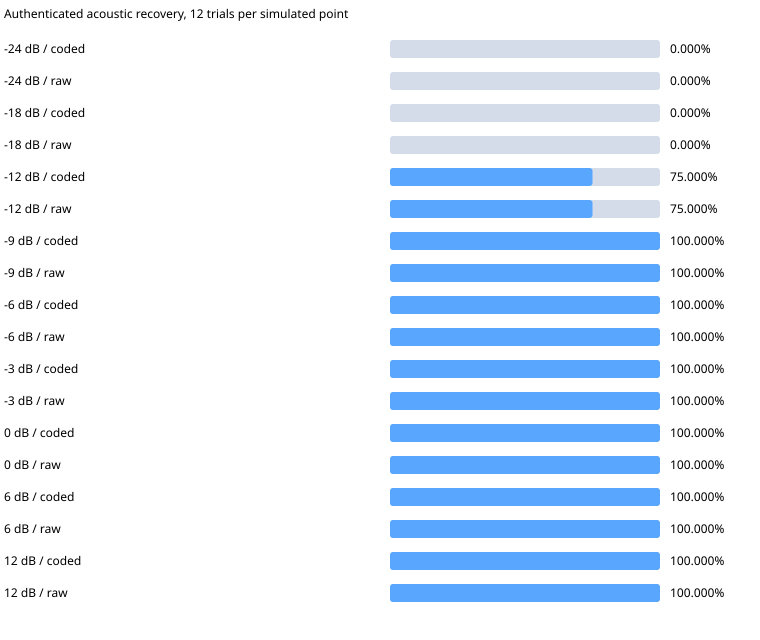

{
  "environment": {
    "system": "Darwin",
    "architecture": "arm64",
    "python": "3.13.18",
    "dependencies": {
      "numpy": "2.3.4",
      "z3-solver": "4.15.3.0",
      "cryptography": "46.0.3"
    }
  },
  "metadata": {
    "seed": 2026,
    "crypto_trials": 1000,
    "acoustic_trials_per_snr": 12,
    "acoustic": [
      {
        "snr_db": -24,
        "mode": "coded",
        "trials": 12,
        "authenticated_recoveries": 0,
        "unsafe_accepts": 0,
        "recovery_rate": 0.0,
        "wilson95_low": 2.7755575615628914e-17,
        "wilson95_high": 0.24249400665524085,
        "airtime_seconds": 3.8666213151927438,
        "plaintext_goodput_bps": 0.0,
        "median_ms": 5.960103999999998,
        "p95_ms": 6.570193899999995,
        "total_ms": 72.40187699999998
      },
      {
        "snr_db": -24,
        "mode": "raw",
        "trials": 12,
        "authenticated_recoveries": 0,
        "unsafe_accepts": 0,
        "recovery_rate": 0.0,
        "wilson

In [1]:
import json, os, subprocess, sys, tempfile
from pathlib import Path
from IPython.display import display, Markdown, SVG

# Run from the bundle root or the paper directory. No personal path is embedded.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "research_common.py").is_file()), None)
if ROOT is None and Path("/kaggle/input").is_dir():
    mounted = list(Path("/kaggle/input").glob("*/research_common.py"))
    mounted += list(Path("/kaggle/input").glob("*/kaggle_submissions/research_common.py"))
    if len(mounted) == 1:
        ROOT = mounted[0].parent
if ROOT is None:
    raise RuntimeError("Open this notebook within the complete research bundle")
sys.path.insert(0, str(ROOT))
from research_common import markdown_table
from publication_builder import comparison_svg

env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1"}
with tempfile.TemporaryDirectory(prefix="research-reproduction-") as temporary:
    output = Path(temporary)
    child = subprocess.run(
        [sys.executable, str(ROOT / 'privacy-first-agentic-ai' / 'privacy_agent_benchmark.py'), "--output", str(output)],
        text=True, capture_output=True, env=env, timeout=600,
    )
    if child.returncode:
        raise RuntimeError("Benchmark failed; inspect the local command output")
    report = json.loads((output / "results.json").read_text())

assert report["schema_version"] == 1
assert report["summary"]
display(Markdown("## Recomputed empirical results\n\n" + markdown_table(report["summary"])))
if "acoustic" in report["metadata"]:
    display(Markdown("## Recomputed acoustic results\n\n" + markdown_table(report["metadata"]["acoustic"])))
display(SVG(comparison_svg('privacy-first-agentic-ai', report)))
print(json.dumps({"environment": report["environment"], "metadata": report["metadata"]}, indent=2))
